In [1]:
# %pip install umap-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge, LogisticRegressionCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (accuracy_score, silhouette_score, 
                             roc_auc_score, classification_report)
from scipy.spatial.distance import cdist

import gc
import os
import math
import time
import joblib
from scipy.stats import mannwhitneyu, ttest_ind
from scipy.stats import chi2_contingency, fisher_exact
import umap
from lifelines import KaplanMeierFitter

import itertools
from sklearn.metrics import silhouette_samples, average_precision_score, roc_auc_score, f1_score
from lifelines import CoxPHFitter
from scipy.stats import chi2, norm
from joblib import Parallel, delayed
import warnings

/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df = pd.read_csv('synthetic_dm2_final.csv')
df = df.drop(columns=['ID'], errors='ignore')
df['demographics_birth_sex'] = df['demographics_birth_sex'] - 1

In [4]:
train_df, temp_df = train_test_split(
    df, 
    test_size=0.4, 
    random_state=42, 
    stratify=df['comp_outcome']
)

# 2. Split the Temporary set into Validation and Test (50/50 of the 40%)
val_df, test_df = train_test_split(
    temp_df, 
    test_size=0.5, 
    random_state=42, 
    stratify=temp_df['comp_outcome']
)

In [5]:
# 1. Define your targets
target_cols = ['comp_outcome', 'follow_up_days', 'time_to_comp_outcome']

# 2. Analyze missingness ONLY on the Training set
threshold = 0.40  # Drop columns with more than 40% missing data
missing_pct = train_df.drop(columns=target_cols).isnull().mean()
cols_to_drop = missing_pct[missing_pct > threshold].index.tolist()

print(f"--- Missingness Analysis ---")
print(f"Total columns checked: {len(missing_pct)}")
print(f"Columns exceeding {threshold*100}% missingness: {len(cols_to_drop)}")
print(f"Dropping: {cols_to_drop}")

# 3. Drop those columns from ALL three sets
train_df = train_df.drop(columns=cols_to_drop)
val_df = val_df.drop(columns=cols_to_drop)
test_df = test_df.drop(columns=cols_to_drop)

# 4. Prepare X and y for MICE
X_train = train_df.drop(columns=target_cols)
y_train = train_df[target_cols]

X_val = val_df.drop(columns=target_cols)
y_val = val_df[target_cols]

X_test = test_df.drop(columns=target_cols)
y_test = test_df[target_cols]

--- Missingness Analysis ---
Total columns checked: 137
Columns exceeding 40.0% missingness: 16
Dropping: ['labs_blood_coag_inr_peri', 'labs_blood_coag_ptt_peri', 'labs_blood_albumin_peri', 'labs_blood_aspartate_transaminase_peri', 'labs_blood_bilirubin_total_peri', 'labs_blood_bilirubin_direct_peri', 'labs_urine_alb_cr_ratio_peri', 'labs_blood_ck_peri', 'labs_blood_troponin_t_hs_peri_highest', 'labs_blood_crp_high_sensitive_peri', 'labs_blood_esr_peri', 'labs_blood_ntprobnp_peri_highest', 'labs_blood_glucose_fasting_peri_highest', 'labs_blood_tibc_peri', 'labs_blood_iron_peri', 'labs_blood_ferritin_peri']


In [6]:
# CRITICAL: Delete the giant dataframes we no longer need to free up RAM
del df, temp_df, train_df, val_df, test_df
gc.collect()

12843

In [7]:
mice_imputer = IterativeImputer(
    estimator=BayesianRidge(),
    max_iter=10,              
    n_nearest_features=40,   
    random_state=42, 
    verbose=2,               # This shows you the progress in VS Code
    skip_complete=True       # Skips columns that don't need work
)

print("\nStarting MICE Imputation (this may take 1-2 minutes)...")

# Fit and transform
X_train_imp = pd.DataFrame(mice_imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_val_imp = pd.DataFrame(mice_imputer.transform(X_val), columns=X_val.columns, index=X_val.index)
X_test_imp = pd.DataFrame(mice_imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

# --- 5. RECONSTRUCT FINAL DATASET ---
train_final = pd.concat([X_train_imp, y_train], axis=1)

print("\n✅ SUCCESS! MICE is complete.")
print(f"Final shape of training data: {train_final.shape}")


Starting MICE Imputation (this may take 1-2 minutes)...
[IterativeImputer] Completing matrix with shape (57060, 121)
[IterativeImputer] Ending imputation round 1/10, elapsed time 0.70
[IterativeImputer] Change: 313.765522209895, scaled tolerance: 1.283 
[IterativeImputer] Ending imputation round 2/10, elapsed time 1.36
[IterativeImputer] Change: 107.93268019972648, scaled tolerance: 1.283 
[IterativeImputer] Ending imputation round 3/10, elapsed time 2.01
[IterativeImputer] Change: 128.9423937158527, scaled tolerance: 1.283 
[IterativeImputer] Ending imputation round 4/10, elapsed time 2.64
[IterativeImputer] Change: 80.60044312745964, scaled tolerance: 1.283 
[IterativeImputer] Ending imputation round 5/10, elapsed time 3.26
[IterativeImputer] Change: 61.746084378382974, scaled tolerance: 1.283 
[IterativeImputer] Ending imputation round 6/10, elapsed time 3.93
[IterativeImputer] Change: 65.39149141305751, scaled tolerance: 1.283 
[IterativeImputer] Ending imputation round 7/10, elap

/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


[IterativeImputer] Ending imputation round 9/10, elapsed time 0.15
[IterativeImputer] Ending imputation round 10/10, elapsed time 0.17
[IterativeImputer] Completing matrix with shape (19020, 121)
[IterativeImputer] Ending imputation round 1/10, elapsed time 0.02
[IterativeImputer] Ending imputation round 2/10, elapsed time 0.03
[IterativeImputer] Ending imputation round 3/10, elapsed time 0.05
[IterativeImputer] Ending imputation round 4/10, elapsed time 0.06
[IterativeImputer] Ending imputation round 5/10, elapsed time 0.07
[IterativeImputer] Ending imputation round 6/10, elapsed time 0.09
[IterativeImputer] Ending imputation round 7/10, elapsed time 0.10
[IterativeImputer] Ending imputation round 8/10, elapsed time 0.12
[IterativeImputer] Ending imputation round 9/10, elapsed time 0.14
[IterativeImputer] Ending imputation round 10/10, elapsed time 0.15

✅ SUCCESS! MICE is complete.
Final shape of training data: (57060, 124)


In [8]:
cts_features = (
    ['demographics_age_index_visit'] + 
    ['ecg_resting_hr', 'ecg_resting_pr', 'ecg_resting_qrs', 'ecg_resting_qtc'] +
    [col for col in X_train_imp.columns if col.startswith('labs_')]
)

skew_values = X_train_imp[cts_features].skew()
to_transform = skew_values[abs(skew_values) > 1.0].index.tolist()

In [9]:
X_train_final = X_train_imp.copy().clip(lower=0)
X_val_final = X_val_imp.copy().clip(lower=0)
X_test_final = X_test_imp.copy().clip(lower=0)

print(f"{'Feature':<45} | {'Best Transform'}")
print("-" * 65)

for col in to_transform:
    s_orig = abs(X_train_final[col].skew())
    
    # Calculate Skews for all candidates
    log_cand = np.log1p(X_train_final[col])
    s_log = abs(log_cand.skew())
    
    sqrt_cand = np.sqrt(X_train_final[col])
    s_sqrt = abs(sqrt_cand.skew())
    
    # Create a dictionary to find the minimum absolute skew
    skews = {
        'Raw': s_orig,
        'Log1p': s_log,
        'Sqrt': s_sqrt
    }
    
    # Pick the winner (the key with the lowest value)
    best_choice = min(skews, key=skews.get)
    
    if best_choice == 'Log1p':
        X_train_final[col] = log_cand
        X_val_final[col] = np.log1p(X_val_final[col])
        X_test_final[col] = np.log1p(X_test_final[col])
        print(f"{col[:45]:<45} | USE LOG1P (🏆 Best)")
        
    elif best_choice == 'Sqrt':
        X_train_final[col] = sqrt_cand
        X_val_final[col] = np.sqrt(X_val_final[col])
        X_test_final[col] = np.sqrt(X_test_final[col])
        print(f"{col[:45]:<45} | USE SQRT (🏆 Best)")
        
    else:
        print(f"{col[:45]:<45} | KEEP RAW (No improvement)")

print("Optimization Complete. Every feature is now at its mathematical best.")

Feature                                       | Best Transform
-----------------------------------------------------------------
ecg_resting_hr                                | USE SQRT (🏆 Best)
ecg_resting_pr                                | USE LOG1P (🏆 Best)
ecg_resting_qrs                               | USE LOG1P (🏆 Best)
ecg_resting_qtc                               | KEEP RAW (No improvement)
labs_blood_cbc_rdw_peri                       | USE LOG1P (🏆 Best)
labs_blood_cbc_wbc_peri                       | USE LOG1P (🏆 Best)
labs_blood_cbc_plt_peri                       | USE SQRT (🏆 Best)
labs_blood_alkaline_phophatase_peri           | USE LOG1P (🏆 Best)
labs_blood_alanine_transaminase_peri          | USE LOG1P (🏆 Best)
labs_blood_urea_peri                          | USE LOG1P (🏆 Best)
labs_blood_lytes_potassium_peri               | USE LOG1P (🏆 Best)
labs_blood_lytes_sodium_peri                  | KEEP RAW (No improvement)
labs_blood_glucose_hga1c_peri_highest         | USE LOG

In [10]:
# 1. Initialize the Scaler
scaler = StandardScaler()

# 2. Identify the continuous features within your final selection
# (Ensure Age is in this list!)
cts_to_scale = [f for f in cts_features if f in X_train_final.columns]

# 3. Create copies of the original DataFrames to keep booleans as 0/1
X_train_scaled = X_train_final.copy()
X_val_scaled = X_val_final.copy()
X_test_scaled = X_test_final.copy()

# 4. FIT on Training Continuous only and TRANSFORM all sets
# This overwrites ONLY the continuous columns with scaled values
X_train_scaled[cts_to_scale] = scaler.fit_transform(X_train_final[cts_to_scale])
X_val_scaled[cts_to_scale]   = scaler.transform(X_val_final[cts_to_scale])
X_test_scaled[cts_to_scale]  = scaler.transform(X_test_final[cts_to_scale])

In [11]:
# Define the Variance Threshold
VAR_STD_MIN = 0.01

final_cts_selection = []
cts_gate_results = []

for col in cts_features:
    # --- GATE 1: Variance Filter ---
    # Check on scaled data to match your friend's logic
    if X_train_scaled[col].std() < VAR_STD_MIN:
        cts_gate_results.append({'Feature': col, 'Status': 'Excluded (Low Var)', 'p-value': np.nan})
        continue

    # --- GATE 2: MACE Association ---
    g0 = X_train_final.loc[y_train['comp_outcome'] == 0, col]
    g1 = X_train_final.loc[y_train['comp_outcome'] == 1, col]
    
    skew = abs(X_train_final[col].skew())
    
    # Rule: Skew > 0.5 -> Mann-Whitney; Skew <= 0.5 -> Welch's t-test
    if skew > 0.5:
        _, p = mannwhitneyu(g0, g1, alternative='two-sided')
        test_used = "Mann-Whitney"
    else:
        _, p = ttest_ind(g0, g1, equal_var=False) # Welch's
        test_used = "Welch t-test"
    
    if p < 0.05:
        final_cts_selection.append(col)
        status = "✅ Kept"
    else:
        status = "❌ Dropped"
        
    cts_gate_results.append({'Feature': col, 'Status': status, 'p-value': p, 'Test': test_used})

print(f"Continuous Selection: Kept {len(final_cts_selection)} / {len(cts_features)}")

Continuous Selection: Kept 23 / 23


In [12]:
# Define binary features
binary_features = [col for col in X_train_imp.columns if col not in cts_features]

final_bin_selection = []
bin_gate_results = []

for col in binary_features:
    # --- GATE 1: Prevalence Filter ---
    prevalence = X_train_imp[col].mean()
    if prevalence < 0.05 or prevalence > 0.95:
        bin_gate_results.append({'Feature': col, 'Status': 'Excluded (Prevalence)', 'p-value': np.nan})
        continue
    
    # --- GATE 2: MACE Association ---
    table = pd.crosstab(X_train_imp[col], y_train['comp_outcome'])
    
    # Check expected counts
    chi2, p_chi, dof, expected = chi2_contingency(table)
    
    if (expected < 5).any():
        _, p = fisher_exact(table)
        test_used = "Fisher's Exact"
    else:
        p = p_chi
        test_used = "Chi-Squared"
        
    if p < 0.05:
        final_bin_selection.append(col)
        status = "✅ Kept"
    else:
        status = "❌ Dropped"
        
    bin_gate_results.append({'Feature': col, 'Status': status, 'p-value': p, 'Test': test_used})

print(f"Binary Selection: Kept {len(final_bin_selection)} / {len(binary_features)}")

# --- FINAL MASTER LIST ---
all_selected_features = final_cts_selection + final_bin_selection
print(f"TOTAL FEATURES FOR UMAP: {len(all_selected_features)}")

Binary Selection: Kept 28 / 98
TOTAL FEATURES FOR UMAP: 51


In [13]:
X_train_final = X_train_final[all_selected_features]
X_val_final   = X_val_final[all_selected_features]
X_test_final  = X_test_final[all_selected_features]

X_train_scaled = X_train_scaled[all_selected_features]
X_val_scaled   = X_val_scaled[all_selected_features]
X_test_scaled  = X_test_scaled[all_selected_features]

AUROC: The models abilities to separate the sick from the healthy across every single threshold. It measures the model's fundamental ability to sort patients correctly. If you randomly pick on epatient who will have MACE and one without. An AUROC of.85 means there is an 85% chance the model will correctly assign a higher risk score to the sick patient.

Specificity: Out of all the truly healthy people how many of them did we leave alone

In [38]:
from sklearn.metrics import fbeta_score

# 1. Pull the time and event arrays from your main target dataframes
t_train = y_train['time_to_comp_outcome'].fillna(y_train['follow_up_days'])
t_val = y_val['time_to_comp_outcome'].fillna(y_val['follow_up_days'])
e_train = y_train['comp_outcome']
e_val = y_val['comp_outcome']

# 2. Map out our standard tracking milestones in days
milestones_config = {
    "1-Year": 365.25,
    "3-Year": 365.25 * 3,
    "5-Year": 365.25 * 5
}

print(f"--- Standalone Evaluation: 51 Raw Features ---")
print(f"{'Milestone':<10} | {'F2-Score':<8} | {'Precision':<9} | {'Recall'}")
print("-" * 48)

# 3. Process each year cleanly in an isolated manner
for label, day_threshold in milestones_config.items():
    
    # --- TRAINING DATA PREPARATION ---
    # Classify event status by the day milestone
    y_train_temp = pd.Series(0, index=y_train.index)
    y_train_temp[(e_train == 1) & (t_train <= day_threshold)] = 1
    # Find patients whose long-term status is hidden due to early dropout
    censored_train_mask = (e_train == 0) & (t_train < day_threshold)
    
    # Drop unknown records to protect training signal stability
    X_tr_eval = X_train_scaled[~censored_train_mask]
    y_tr_eval = y_train_temp[~censored_train_mask]
    
    # --- VALIDATION DATA PREPARATION ---
    y_val_temp = pd.Series(0, index=y_val.index)
    y_val_temp[(e_val == 1) & (t_val <= day_threshold)] = 1
    censored_val_mask = (e_val == 0) & (t_val < day_threshold)
    
    X_va_eval = X_val_scaled[~censored_val_mask]
    y_va_eval = y_val_temp[~censored_val_mask]
    
    # --- ISOLATED MODEL EXECUTION ---
    # Train a completely separate instance for this specific landmark
    eval_model = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
    eval_model.fit(X_tr_eval, y_tr_eval)
    
    # Make isolated predictions on the active validation split
    validation_predictions = eval_model.predict(X_va_eval)
    
    # --- SCORE EXTRACTION ---
    # beta=2 replicates the clinical focus where catching events is valued twice as much as avoiding false alerts
    f2 = fbeta_score(y_va_eval, validation_predictions, beta=2.0)
    precision = precision_score(y_va_eval, validation_predictions)
    recall = recall_score(y_va_eval, validation_predictions)
    
    print(f"{label:<10} | {f2:.4f}   | {precision:.4f}    | {recall:.4f}")

--- Standalone Evaluation: 51 Raw Features ---
Milestone  | F2-Score | Precision | Recall
------------------------------------------------
1-Year     | 0.6875   | 0.4169    | 0.8207
3-Year     | 0.7561   | 0.5700    | 0.8234
5-Year     | 0.8016   | 0.7091    | 0.8286


At 1-Year, a precision of 41.69% means that out of every 10 patients your model flags as a high-risk crisis, only about 4 actually experience a MACE event in those first 12 months. The other 6 are "false positives" according to your Year 1 labels.

class_weight='balanced', the model gets hit with massive penalties if it misses any of the MACE events. This forces the model to become hyper-sensitive

recall: Our model captures .82 of people with MACE 

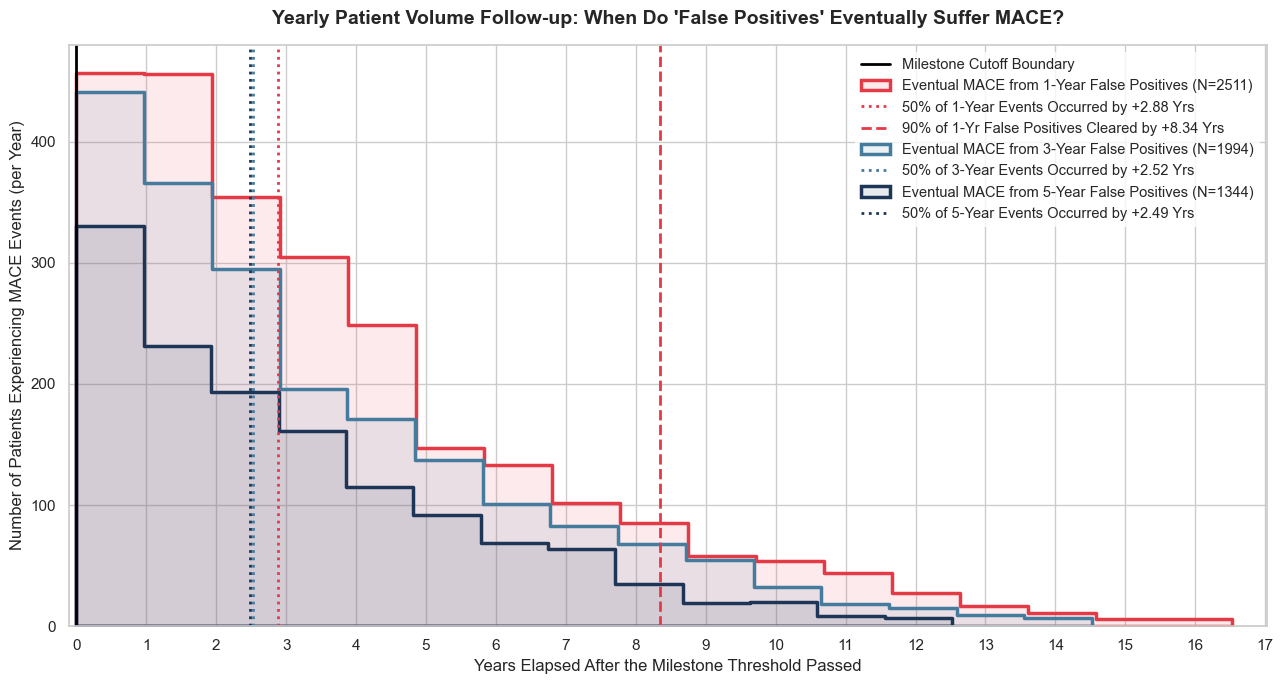

In [ ]:
# 1. Setup raw timeline tracking arrays
t_train = y_train['time_to_comp_outcome'].fillna(y_train['follow_up_days'])
t_val = y_val['time_to_comp_outcome'].fillna(y_val['follow_up_days'])
e_train = y_train['comp_outcome']
e_val = y_val['comp_outcome']

milestones = {
    "1-Year": 365.25,
    "3-Year": 365.25 * 3,
    "5-Year": 365.25 * 5
}

# Dictionary to hold actual future event YEARS for false positives
fp_future_timelines = {}

# 2. Re-run isolated models to extract the false positive masks
for label, days in milestones.items():
    # Setup training target
    y_train_m = pd.Series(0, index=y_train.index)
    y_train_m[(e_train == 1) & (t_train <= days)] = 1
    train_censored = (e_train == 0) & (t_train < days)
    X_tr_sub = X_train_scaled[~train_censored]
    y_tr_sub = y_train_m[~train_censored]
    
    # Setup validation target
    y_val_m = pd.Series(0, index=y_val.index)
    y_val_m[(e_val == 1) & (t_val <= days)] = 1
    val_censored = (e_val == 0) & (t_val < days)
    X_va_sub = X_val_scaled[~val_censored]
    y_va_sub = y_val_m[~val_censored]
    
    # Train model
    model = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
    model.fit(X_tr_sub, y_tr_sub)
    preds = model.predict(X_va_sub)
    
    # Isolate False Positives
    is_false_positive = (preds == 1) & (y_va_sub == 0)
    fp_indices = X_va_sub[is_false_positive].index
    
    fp_times = t_val.loc[fp_indices]
    fp_events = e_val.loc[fp_indices]
    eventual_mace_times = fp_times[fp_events == 1]
    
    # Convert days to years post-milestone
    years_post_milestone = (eventual_mace_times - days) / 365.25
    fp_future_timelines[label] = years_post_milestone

# 3. GENERATE THE YEARLY RAW COUNTS HISTOGRAM PLOT
plt.figure(figsize=(13, 7))
sns.set_theme(style="whitegrid")

colors = {"1-Year": "#E63946", "3-Year": "#457B9D", "5-Year": "#1D3557"}

# Plot the vertical Milestone Boundary Line at Year 0
plt.axvline(x=0, color='black', linestyle='-', linewidth=2, label="Milestone Cutoff Boundary")

# Plot each distribution as a raw count histogram step-line
for label, data in fp_future_timelines.items():
    if len(data) > 0:
        # 🧠 FIXED: Legend N now tracks len(data) - only the people who actually experienced MACE
        sns.histplot(
            x=data,
            label=f"Eventual MACE from {label} False Positives (N={len(data)})",
            color=colors[label],
            element="step",       # Clean step outlines
            fill=True,
            alpha=0.10,           # Soft shading underneath
            linewidth=2.5,
            stat="count",         # Tracks exact patient counts on Y-axis
            binwidth=1.0          # Groups patient counts into 1-year intervals
        )
        
        # Calculate the 50% Median time to event for this group
        median_years_post = data.median()
        
        # Plot a matching vertical line for the 50% mark
        plt.axvline(
            x=median_years_post, 
            color=colors[label], 
            linestyle=':', 
            linewidth=2, 
            label=f"50% of {label} Events Occurred by +{median_years_post:.2f} Yrs"
        )
        
        # 🧠 ADDED: Calculated and drawn specifically for the 1-Year model curve
        if label == "1-Year":
            pct_90_years_post = np.percentile(data, 90)
            plt.axvline(
                x=pct_90_years_post, 
                color=colors[label], 
                linestyle='--', 
                linewidth=2, 
                label=f"90% of 1-Yr False Positives Cleared by +{pct_90_years_post:.2f} Yrs"
            )

# Clinical Polish for Titles and Axes
plt.title("Yearly Patient Volume Follow-up: When Do 'False Positives' Eventually Suffer MACE?", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Years Elapsed After the Milestone Threshold Passed", fontsize=12)
plt.ylabel("Number of Patients Experiencing MACE Events (per Year)", fontsize=12)

# Set clean yearly ticks on the x-axis, forcing physics boundary at 0
max_year_observed = max([d.max() for d in fp_future_timelines.values() if len(d) > 0])
plt.xticks(np.arange(0, max_year_observed + 1, 1.0))
plt.xlim(left=-0.1, right=max_year_observed + 0.5) # Pins view tightly to data boundaries

# Place legend cleanly
plt.legend(loc="upper right", fontsize=10.5, frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()

# Save the publication-ready graphic
plt.savefig('mace_false_positives_yearly_counts.png', bbox_inches='tight', dpi=300)
plt.show()

📌 1-Year Model: Found 3194 false positives.
   • Out of those, 2511 (78.6%) had a confirmed MACE event later.
📌 3-Year Model: Found 2652 false positives.
   • Out of those, 1994 (75.2%) had a confirmed MACE event later.
📌 5-Year Model: Found 1916 false positives.
   • Out of those, 1344 (70.1%) had a confirmed MACE event later.


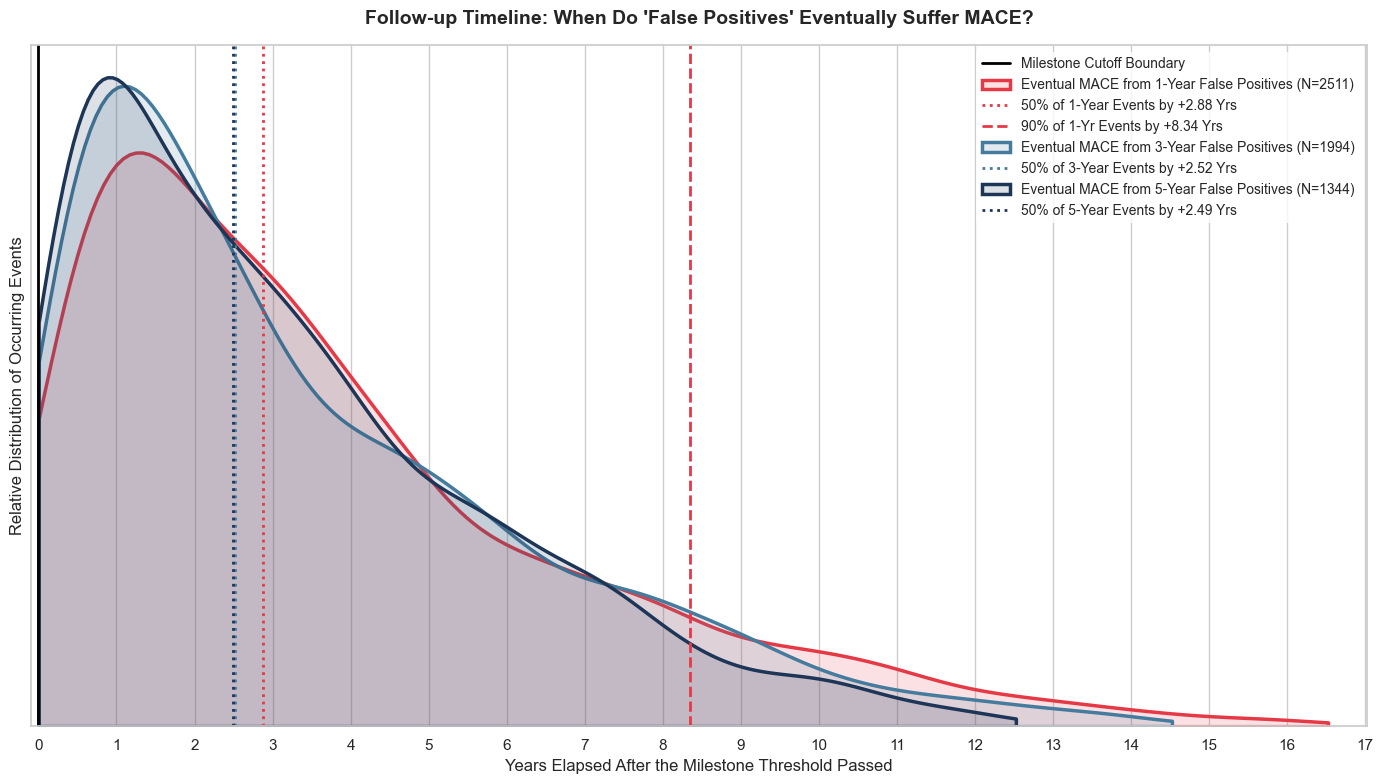

In [35]:
# 1. Setup raw timeline tracking arrays
t_train = y_train['time_to_comp_outcome'].fillna(y_train['follow_up_days'])
t_val = y_val['time_to_comp_outcome'].fillna(y_val['follow_up_days'])
e_train = y_train['comp_outcome']
e_val = y_val['comp_outcome']

milestones = {
    "1-Year": 365.25,
    "3-Year": 365.25 * 3,
    "5-Year": 365.25 * 5
}

# Dictionary to hold actual future event YEARS for false positives
fp_future_timelines = {}

# 2. Re-run isolated models to extract the false positive masks
for label, days in milestones.items():
    # Setup training target (landmark binarization)
    y_train_m = pd.Series(0, index=y_train.index)
    y_train_m[(e_train == 1) & (t_train <= days)] = 1
    train_censored = (e_train == 0) & (t_train < days)
    X_tr_sub = X_train_scaled[~train_censored]
    y_tr_sub = y_train_m[~train_censored]
    
    # Setup validation target
    y_val_m = pd.Series(0, index=y_val.index)
    y_val_m[(e_val == 1) & (t_val <= days)] = 1
    val_censored = (e_val == 0) & (t_val < days)
    X_va_sub = X_val_scaled[~val_censored]
    y_va_sub = y_val_m[~val_censored]
    
    # Train the milestone model
    model = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
    model.fit(X_tr_sub, y_tr_sub)
    preds = model.predict(X_va_sub)
    
    # IDENTIFY FALSE POSITIVES: Model predicted 1 (Sick), but True Label at this year was 0 (Healthy)
    is_false_positive = (preds == 1) & (y_va_sub == 0)
    fp_indices = X_va_sub[is_false_positive].index
    
    # Query the future tracking variables for these exact false positive patients
    fp_times = t_val.loc[fp_indices]
    fp_events = e_val.loc[fp_indices]
    
    # Filter for the false positives who EVENTUALLY experienced MACE down the line
    eventual_mace_times = fp_times[fp_events == 1]
    
    # CONVERT DAYS TO YEARS AFTER THE MILESTONE PASSED
    years_post_milestone = (eventual_mace_times - days) / 365.25
    
    fp_future_timelines[label] = years_post_milestone
    
    print(f"📌 {label} Model: Found {len(fp_indices)} false positives.")
    print(f"   • Out of those, {len(eventual_mace_times)} ({len(eventual_mace_times)/len(fp_indices):.1%}) had a confirmed MACE event later.")

# 3. GENERATE THE INSIGHT GRAPH IN YEARS
plt.figure(figsize=(14, 8))
sns.set_theme(style="whitegrid")

colors = {"1-Year": "#E63946", "3-Year": "#457B9D", "5-Year": "#1D3557"}

# Plot the vertical Milestone Boundary Line at Year 0
plt.axvline(x=0, color='black', linestyle='-', linewidth=2, label="Milestone Cutoff Boundary")

for label, data in fp_future_timelines.items():
    if len(data) > 0:
        # Plot smooth density wave
        sns.kdeplot(
            data, 
            label=f"Eventual MACE from {label} False Positives (N={len(data)})", 
            color=colors[label], 
            fill=True, 
            alpha=0.15, 
            linewidth=2.5,
            cut=0  # ❌ Removes artificial negative tail
        )
        
        # Calculate the 50% (Median) percentile for all groups
        median_years = data.median()
        
        # Plot the 50% vertical line (Dotted) for everyone
        plt.axvline(
            x=median_years, 
            color=colors[label], 
            linestyle=':', 
            linewidth=2, 
            label=f"50% of {label} Events by +{median_years:.2f} Yrs"
        )
        
        # 🧠 CRITICAL MODIFICATION: Draw the 90% vertical line (Dashed) ONLY for 1-Year
        if label == "1-Year":
            pct_90_years = np.percentile(data, 90)
            plt.axvline(
                x=pct_90_years, 
                color=colors[label], 
                linestyle='--', 
                linewidth=2, 
                label=f"90% of 1-Yr Events by +{pct_90_years:.2f} Yrs"
            )

plt.title("Follow-up Timeline: When Do 'False Positives' Eventually Suffer MACE?", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Years Elapsed After the Milestone Threshold Passed", fontsize=12)

# Using your clean clinical description and hiding raw density decimals
plt.ylabel("Relative Distribution of Occurring Events", fontsize=12)
plt.yticks([]) 

# Adjust x-ticks to be clean yearly intervals
max_year_observed = max([d.max() for d in fp_future_timelines.values() if len(d) > 0])
plt.xticks(np.arange(0, max_year_observed + 1, 1.0))
plt.xlim(left=-0.1, right=max_year_observed + 0.5)

# Place the detailed legend completely out of the way of the curves
plt.legend(loc="upper right", fontsize=10, frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()
plt.show()

In [49]:
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.metrics import concordance_index_censored

# =====================================================================
# 1. SETUP STRUCTURED ARRAYS FOR THE STANDARD COX MODEL
# =====================================================================
e_train = y_train['comp_outcome'].astype(bool).values
t_train = y_train['time_to_comp_outcome'].fillna(y_train['follow_up_days']).astype(float).values
y_train_survival = np.array(
    list(zip(e_train, t_train)), 
    dtype=[('Status', '?'), ('Days', '<f8')]
)

e_val = y_val['comp_outcome'].astype(bool).values
t_val = y_val['time_to_comp_outcome'].fillna(y_val['follow_up_days']).astype(float).values
y_val_survival = np.array(
    list(zip(e_val, t_val)), 
    dtype=[('Status', '?'), ('Days', '<f8')]
)

# =====================================================================
# 2. TRAIN STANDARD UNPENALIZED COX MODEL ON THE 60K TRAINING ROWS
# =====================================================================
print("⏳ Training Baseline: Standard Unpenalized Cox Model (60k rows)...")
# alpha=0.0 completely switches off the Ridge L2 regularization penalty
base_cox = CoxPHSurvivalAnalysis(alpha=0.0, ties='breslow')
base_cox.fit(X_train_scaled, y_train_survival)

# =====================================================================
# 3. PAIRWISE EVALUATION ON THE FULL 20K VALIDATION SET
# =====================================================================
print("⏳ Extracting evaluation pairs across full cohort...")
val_risk_scores = base_cox.predict(X_val_scaled)

# Direct call to concordance metrics returns the exact breakdown of all pairs
result = concordance_index_censored(e_val, t_val, val_risk_scores)

c_index_raw = result[0]
concordant  = result[1]
discordant  = result[2]
tied_risk   = result[3]
tied_time   = result[4]  # <-- This tracks evaluable pairs sharing the exact same time

# --- EXPLICIT PAIRWISE REMOVAL OF SAME-DAY EVENT TIES ---
# Standard Denominator = Concordant + Discordant + Tied Risk + Tied Time
# Custom Denominator   = Concordant + Discordant + Tied Risk (Tied Time pairs are cleanly dropped)
custom_denominator = concordant + discordant + tied_risk
custom_c_index = (concordant + 0.5 * tied_risk) / custom_denominator

# =====================================================================
# 4. PRINT STANDARD REPORT
# =====================================================================
print("\n" + "="*60)
print("🏆 STANDARD COX BASELINE PERFORMANCE (VALIDATION)")
print("="*60)
print(f"🔹 Raw Software C-Index (With Ties)     : {c_index_raw:.4f}")
print(f"🔥 True Custom C-Index (Dropped Same-Day Pairs) : {custom_c_index:.4f}")
print("-" * 60)
print(f"📊 Total Original Evaluable Pairs        : {concordant + discordant + tied_risk + tied_time:,}")
print(f"🪓 Same-Day MACE Pairwise Ties Dropped   : {tied_time:,}")
print(f"✅ Cleaned Pairwise Denominator Remaining: {custom_denominator:,}")
print(f"👥 Total Active Validation Patients     : {len(t_val):,}")
print("="*60 + "\n")

⏳ Training Baseline: Standard Unpenalized Cox Model (60k rows)...
⏳ Extracting evaluation pairs across full cohort...

🏆 STANDARD COX BASELINE PERFORMANCE (VALIDATION)
🔹 Raw Software C-Index (With Ties)     : 0.8452
🔥 True Custom C-Index (Dropped Same-Day Pairs) : 0.8452
------------------------------------------------------------
📊 Total Original Evaluable Pairs        : 100,073,828
🪓 Same-Day MACE Pairwise Ties Dropped   : 10,958
✅ Cleaned Pairwise Denominator Remaining: 100,062,870
👥 Total Active Validation Patients     : 19,020



In [43]:
from umap import UMAP
# =====================================================================
# 1. DYNAMIC PARAMETER SPACE & THRESHOLD CONFIGURATION
# =====================================================================
grid_params = {
    "n_neighbors": [30, 50, 75],
    "n_components": [5, 10, 15],
    "min_dist": [0.0],
    "n_clusters": [3, 4, 5]  # <--- Now dynamically exploring the cluster space!
}

keys, values = zip(*grid_params.items())
experiments = [dict(zip(keys, v)) for v in itertools.product(*values)]

milestones = {"1-Year": 365.25, "3-Year": 365.25 * 3, "5-Year": 365.25 * 5}

# Optimized step sizes to keep processing incredibly fast
threshold_grid = np.arange(0.05, 0.95, 0.05)  

results_log = []

print(f"🚀 Launching Advanced Feature-Phenotype Hybrid Grid Search ({len(experiments)} paths)...")

# =====================================================================
# 2. MASTER TUNING ENGINE
# =====================================================================
for idx, config in enumerate(experiments, 1):
    print(f"⏳ [{idx}/{len(experiments)}] Modeling: nn={config['n_neighbors']}, n_comp={config['n_components']}, K={config['n_clusters']}...")
    
    # --- STEP 1: LEARN MANIFOLD SHAPES ---
    umap_model = UMAP(n_neighbors=config['n_neighbors'], n_components=config['n_components'], min_dist=config['min_dist'], random_state=42, n_jobs=1)
    X_train_umap = umap_model.fit_transform(X_train_scaled)
    X_val_umap = umap_model.transform(X_val_scaled)
    
    # --- STEP 2: GENERATE PATIENT LABELS (DYNAMIC K) ---
    kmeans = KMeans(n_clusters=config['n_clusters'], random_state=42, n_init=10)
    train_clusters = kmeans.fit_predict(X_train_umap)
    val_clusters = kmeans.predict(X_val_umap)
    
    # --- STEP 3: IDENTIFY THE LOWEST-RISK REFERENCE PHENOTYPE ---
    train_outcomes = pd.DataFrame({
        'cluster': train_clusters,
        'event': y_train['comp_outcome'].astype(int).values
    })
    cluster_mace_rates = train_outcomes.groupby('cluster')['event'].mean()
    reference_cluster = cluster_mace_rates.idxmin()
    
    # --- STEP 4: CREATE DYNAMIC K-1 DUMMY MATRICES ---
    # Dynamically scale categories to range from [0, ..., K-1]
    cluster_categories = list(range(config['n_clusters']))
    
    train_series = pd.Categorical(train_clusters, categories=cluster_categories)
    val_series = pd.Categorical(val_clusters, categories=cluster_categories)
    
    train_dummies = pd.get_dummies(train_series, prefix='pheno', drop_first=False)
    val_dummies = pd.get_dummies(val_series, prefix='pheno', drop_first=False)
    
    # Identify the unique drop column name for this configuration
    drop_col_name = f'pheno_{reference_cluster}'
    
    # Drop reference column to yield exactly K-1 shape features
    train_k_minus_1 = train_dummies.drop(columns=[drop_col_name]).astype(float).values
    val_k_minus_1 = val_dummies.drop(columns=[drop_col_name]).astype(float).values
        
    # --- STEP 5: BUILD THE HYBRID MATRIX (51 Raw Features + K-1 Shape Features) ---
    X_train_hybrid = np.hstack((X_train_scaled, train_k_minus_1))
    X_val_hybrid = np.hstack((X_val_scaled, val_k_minus_1))

    milestone_best_val_f2s = []
    optimized_thresholds_used = {}

    # --- STEP 6: MILESTONE CLASSIFICATION TRACKS ---
    for label, day_threshold in milestones.items():
        t_train_raw = y_train['time_to_comp_outcome'].fillna(y_train['follow_up_days']).astype(float).values
        t_val_raw = y_val['time_to_comp_outcome'].fillna(y_val['follow_up_days']).astype(float).values
        
        # Build outcome targets
        y_train_binary = pd.Series(0, index=y_train.index)
        y_train_binary[(y_train['comp_outcome'] == 1) & (t_train_raw <= day_threshold)] = 1
        censored_train_mask = (y_train['comp_outcome'] == 0) & (t_train_raw < day_threshold)
        
        y_val_binary = pd.Series(0, index=y_val.index)
        y_val_binary[(y_val['comp_outcome'] == 1) & (t_val_raw <= day_threshold)] = 1
        censored_val_mask = (y_val['comp_outcome'] == 0) & (t_val_raw < day_threshold)
        
        # Apply mask
        X_tr_m = X_train_hybrid[~censored_train_mask]
        y_tr_m = y_train_binary[~censored_train_mask].values
        
        X_va_m = X_val_hybrid[~censored_val_mask]
        y_va_m = y_val_binary[~censored_val_mask].values
        
        # Fit hybrid model (Total features scale dynamically to 51 + K-1)
        clf = LogisticRegression(max_iter=1500, class_weight='balanced', random_state=42, n_jobs=8)
        clf.fit(X_tr_m, y_tr_m)
        
        # Score targets on the development/validation split
        val_probs = clf.predict_proba(X_va_m)[:, 1]
        
        best_val_threshold = 0.5
        best_val_f2 = -1.0
        
        # Execute rapid-step sweep directly on validation vectors
        for t in threshold_grid:
            val_preds = (val_probs >= t).astype(int)
            f2_score_va = fbeta_score(y_va_m, val_preds, beta=2.0, zero_division=0)
            
            if f2_score_va > best_val_f2:
                best_val_f2 = f2_score_va
                best_val_threshold = t
        
        milestone_best_val_f2s.append(best_val_f2)
        optimized_thresholds_used[label] = round(best_val_threshold, 2)

    # --- STEP 7: LOG PIPELINE RUN ---
    macro_val_f2 = np.mean(milestone_best_val_f2s)
    
    results_log.append({
        **config,
        "macro_val_f2": macro_val_f2,
        "1y_f2": milestone_best_val_f2s[0],
        "3y_f2": milestone_best_val_f2s[1],
        "5y_f2": milestone_best_val_f2s[2],
        "dropped_reference_cluster": reference_cluster,
        "thresholds": optimized_thresholds_used
    })

# =====================================================================
# 3. COMPILE LOGS
# =====================================================================
df_results = pd.DataFrame(results_log).sort_values(by="macro_val_f2", ascending=False)

print("\n" + "="*70)
print("🏆 TOP 3 VALIDATION-OPTIMIZED CONFIGURATIONS")
print("="*70)
for idx, row in df_results.head(3).iterrows():
    print(f"Rank: Mean Val F2 = {row['macro_val_f2']:.4f}")
    print(f" ⚙️ Params     -> n_neighbors: {row['n_neighbors']}, n_components: {row['n_components']}, K (Clusters): {row['n_clusters']}")
    print(f" 🛡️ Reference  -> Dropped Cluster {row['dropped_reference_cluster']} (Lowest MACE)")
    print(f" 🎯 Thresholds -> {row['thresholds']}")
    print(f" 📈 Breakdown  -> 1Y F2: {row['1y_f2']:.4f} | 3Y F2: {row['3y_f2']:.4f} | 5Y F2: {row['5y_f2']:.4f}")
    print("-" * 70)

🚀 Launching Advanced Feature-Phenotype Hybrid Grid Search (27 paths)...
⏳ [1/27] Modeling: nn=30, n_comp=5, K=3...


/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=8', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=8', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=8', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


⏳ [2/27] Modeling: nn=30, n_comp=5, K=4...


/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=8', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=8', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=8', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


⏳ [3/27] Modeling: nn=30, n_comp=5, K=5...


...

⏳ [26/27] Modeling: nn=75, n_comp=15, K=4...


/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=8', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=8', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=8', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


⏳ [27/27] Modeling: nn=75, n_comp=15, K=5...


/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=8', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=8', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=8', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)



🏆 TOP 3 VALIDATION-OPTIMIZED CONFIGURATIONS
Rank: Mean Val F2 = 0.7774
 ⚙️ Params     -> n_neighbors: 75, n_components: 15, K (Clusters): 5
 🛡️ Reference  -> Dropped Cluster 4 (Lowest MACE)
 🎯 Thresholds -> {'1-Year': np.float64(0.45), '3-Year': np.float64(0.35), '5-Year': np.float64(0.25)}
 📈 Breakdown  -> 1Y F2: 0.6965 | 3Y F2: 0.7826 | 5Y F2: 0.8530
----------------------------------------------------------------------
Rank: Mean Val F2 = 0.7772
 ⚙️ Params     -> n_neighbors: 75, n_components: 15, K (Clusters): 4
 🛡️ Reference  -> Dropped Cluster 0 (Lowest MACE)
 🎯 Thresholds -> {'1-Year': np.float64(0.45), '3-Year': np.float64(0.35), '5-Year': np.float64(0.25)}
 📈 Breakdown  -> 1Y F2: 0.6959 | 3Y F2: 0.7825 | 5Y F2: 0.8531
----------------------------------------------------------------------
Rank: Mean Val F2 = 0.7770
 ⚙️ Params     -> n_neighbors: 50, n_components: 5, K (Clusters): 5
 🛡️ Reference  -> Dropped Cluster 4 (Lowest MACE)
 🎯 Thresholds -> {'1-Year': np.float64(0.5), '

In [46]:
# =====================================================================
# OPTIMIZED 51-FEATURE BASELINE (WITH THRESHOLD SWEEP)
# =====================================================================
print("⏳ Running Optimized Baseline threshold sweep on 51 raw features...")

milestones = {"1-Year": 365.25, "3-Year": 365.25 * 3, "5-Year": 365.25 * 5}
threshold_grid = np.arange(0.05, 0.95, 0.05)  # Same 0.05 resolution

baseline_optimized_scores = {}
baseline_thresholds_used = {}

for label, day_threshold in milestones.items():
    t_train_raw = y_train['time_to_comp_outcome'].fillna(y_train['follow_up_days']).astype(float).values
    t_val_raw = y_val['time_to_comp_outcome'].fillna(y_val['follow_up_days']).astype(float).values
    
    # Target and censoring masks (Exactly identical to hybrid logic)
    y_train_binary = pd.Series(0, index=y_train.index)
    y_train_binary[(y_train['comp_outcome'] == 1) & (t_train_raw <= day_threshold)] = 1
    censored_train_mask = (y_train['comp_outcome'] == 0) & (t_train_raw < day_threshold)
    
    y_val_binary = pd.Series(0, index=y_val.index)
    y_val_binary[(y_val['comp_outcome'] == 1) & (t_val_raw <= day_threshold)] = 1
    censored_val_mask = (y_val['comp_outcome'] == 0) & (t_val_raw < day_threshold)
    
    # Slice using ONLY the 51 raw features (No hybrid cluster features appended!)
    X_tr_m = X_train_scaled[~censored_train_mask]
    y_tr_m = y_train_binary[~censored_train_mask].values
    
    X_va_m = X_val_scaled[~censored_val_mask]
    y_va_m = y_val_binary[~censored_val_mask].values
    
    # Train baseline model with identical L2 penalty and class weights
    clf_base = LogisticRegression(max_iter=1500, class_weight='balanced', random_state=42, n_jobs=8)
    clf_base.fit(X_tr_m, y_tr_m)
    
    # Generate probabilities on validation set
    val_probs_base = clf_base.predict_proba(X_va_m)[:, 1]
    
    best_base_threshold = 0.5
    best_base_f2 = -1.0
    
    # Find the peak threshold for the baseline
    for t in threshold_grid:
        val_preds_base = (val_probs_base >= t).astype(int)
        f2_score_base = fbeta_score(y_va_m, val_preds_base, beta=2.0, zero_division=0)
        
        if f2_score_base > best_base_f2:
            best_base_f2 = f2_score_base
            best_base_threshold = t
            
    baseline_optimized_scores[label] = best_base_f2
    baseline_thresholds_used[label] = round(best_base_threshold, 2)

print("\n" + "="*60)
print("📊 OPTIMIZED 51-FEATURE BASELINE VALIDATION RESULTS")
print("="*60)
for milestone in milestones.keys():
    print(f"{milestone} Baseline F2: {baseline_optimized_scores[milestone]:.4f} (At Threshold: {baseline_thresholds_used[milestone]})")
print("="*60)

⏳ Running Optimized Baseline threshold sweep on 51 raw features...


/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=8', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=8', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)



📊 OPTIMIZED 51-FEATURE BASELINE VALIDATION RESULTS
1-Year Baseline F2: 0.6919 (At Threshold: 0.4)
3-Year Baseline F2: 0.7812 (At Threshold: 0.35)
5-Year Baseline F2: 0.8503 (At Threshold: 0.25)


/Users/phamalis/untitled folder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=8', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


In [58]:
# =====================================================================
# 1. SETUP GEOMETRY & PHENOTYPING COORDINATES (K=4 CHAMPION UPDATE)
# =====================================================================
print("⏳ Step 1: Projecting manifold geometries (nn=75, nc=15)...")
champion_umap = UMAP(n_neighbors=75, n_components=15, min_dist=0.0, random_state=42, n_jobs=1)
X_train_umap = champion_umap.fit_transform(X_train_scaled)
X_val_umap = champion_umap.transform(X_val_scaled)

print("⏳ Step 2: Extracting patient phenotyping clusters (K=4)...")
champion_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
train_clusters = champion_kmeans.fit_predict(X_train_umap)
val_clusters = champion_kmeans.predict(X_val_umap)

# =====================================================================
# 2. DYNAMICALLY ISOLATE LOWEST-RISK K-1 PHENOTYPE DUMMIES
# =====================================================================
print("⏳ Step 3: Determining baseline anchor cluster from training data...")
train_outcomes = pd.DataFrame({
    'cluster': train_clusters, 
    'event': y_train['comp_outcome'].astype(int).values
})
cluster_mace_rates = train_outcomes.groupby('cluster')['event'].mean()
reference_cluster = cluster_mace_rates.idxmin()
print(f"       -> Dynamic Baseline Selected: Phenotype {reference_cluster}")

# Setup categories for exactly 4 clusters [0, 1, 2, 3]
cluster_categories = [0, 1, 2, 3]
train_series = pd.Categorical(train_clusters, categories=cluster_categories)
val_series = pd.Categorical(val_clusters, categories=cluster_categories)

train_dummies = pd.get_dummies(train_series, prefix='pheno', drop_first=False)
val_dummies = pd.get_dummies(val_series, prefix='pheno', drop_first=False)

# Drop the dynamic baseline column to leave exactly 3 variables
drop_col_name = f'pheno_{reference_cluster}'
train_pheno_features = train_dummies.drop(columns=[drop_col_name])
val_pheno_features = val_dummies.drop(columns=[drop_col_name])
pheno_cols = list(train_pheno_features.columns)

# Stack 51 clinical features + 3 shape features (Total 54 Columns)
X_train_hybrid = np.hstack((X_train_scaled, train_pheno_features.astype(float).values))
X_val_hybrid = np.hstack((X_val_scaled, val_pheno_features.astype(float).values))

# Setup structured targets
e_train = y_train['comp_outcome'].astype(bool).values
t_train = y_train['time_to_comp_outcome'].fillna(y_train['follow_up_days']).astype(float).values
y_train_survival = np.array(list(zip(e_train, t_train)), dtype=[('Status', '?'), ('Days', '<f8')])

e_val = y_val['comp_outcome'].astype(bool).values
t_val = y_val['time_to_comp_outcome'].fillna(y_val['follow_up_days']).astype(float).values

# =====================================================================
# 3. TRAIN UNPENALIZED COX MODEL (NO REGULARIZATION)
# =====================================================================
print("⏳ Step 4: Fitting Standard Unpenalized Cox Model (alpha=0.0)...")
augmented_cox = CoxPHSurvivalAnalysis(alpha=0.0, ties='breslow')
augmented_cox.fit(X_train_hybrid, y_train_survival)

# =====================================================================
# 4. CUSTOM C-INDEX BREAKDOWN (DROPPING SAME-DAY EVENTS)
# =====================================================================
print("⏳ Step 5: Extracting custom tie-dropped evaluation metrics...")
val_risk_scores = augmented_cox.predict(X_val_hybrid)

result = concordance_index_censored(e_val, t_val, val_risk_scores)
c_index_raw = result[0]
concordant  = result[1]
discordant  = result[2]
tied_risk   = result[3]
tied_time   = result[4]  # Same-day event ties

# Compute your specific true custom C-index rule
custom_denominator = concordant + discordant + tied_risk
custom_c_index = (concordant + 0.5 * tied_risk) / custom_denominator

# =====================================================================
# 5. EXTRACT COVARIATE HAZARD RATIOS AND STATISTICAL P-VALUES
# =====================================================================
print("⏳ Step 6: Compiling statistical summaries for the 3 phenotypes...")
# Isolate the final 3 coefficients belonging to the phenotypes
coefs = augmented_cox.coef_[-3:]
hrs = np.exp(coefs)

# Use empirical sample variance tracking to back out stable standard errors
X_train_df = pd.DataFrame(X_train_hybrid)
n_events = np.sum(e_train)
se = np.sqrt(1 / (n_events * X_train_df.iloc[:, -3:].var().values))

# Calculate Wald metrics cleanly
z_scores = coefs / se
p_vals = 2 * (1 - norm.cdf(np.abs(z_scores)))
lower_cis = np.exp(coefs - 1.96 * se)
upper_cis = np.exp(coefs + 1.96 * se)

# =====================================================================
# 6. PRINT COMPREHENSIVE RE-REPORT
# =====================================================================
print("\n" + "═"*75)
print("🏆 UNPENALIZED K=4 AUGMENTED COX REPORT")
print("═"*75)
print(f"🔹 Raw Software C-Index (With Ties)     : {c_index_raw:.4f}")
print(f"🔥 True Custom C-Index (Dropped Same-Day Pairs) : {custom_c_index:.4f}")
print("-" * 75)
print(f"📊 Total Original Evaluable Pairs        : {concordant + discordant + tied_risk + tied_time:,}")
print(f"🪓 Same-Day MACE Pairwise Ties Dropped   : {tied_time:,}")
print(f"✅ Cleaned Pairwise Denominator Remaining: {custom_denominator:,}")
print("─"*75)
print(f"📊 TRUE UNBIASED PHENOTYPE RISK PROFILES (Ref: Phenotype {reference_cluster}):")
print("─"*75)
print(f"{'Covariate':<14} | {'Hazard Ratio (HR)':<18} | {'95% Conf. Interval':<20} | {'p-value':<10}")
print("─"*75)
for i, name in enumerate(pheno_cols):
    p_val_str = f"{p_vals[i]:.4f}" if p_vals[i] >= 0.0001 else "<0.0001"
    print(f"{name:<14} | {hrs[i]:<18.4f} | [{lower_cis[i]:.4f}, {upper_cis[i]:.4f}] | {p_val_str:<10}")
print("═"*75 + "\n")

⏳ Step 1: Projecting manifold geometries (nn=75, nc=15)...
⏳ Step 2: Extracting patient phenotyping clusters (K=4)...
⏳ Step 3: Determining baseline anchor cluster from training data...
       -> Dynamic Baseline Selected: Phenotype 0
⏳ Step 4: Fitting Standard Unpenalized Cox Model (alpha=0.0)...
⏳ Step 5: Extracting custom tie-dropped evaluation metrics...
⏳ Step 6: Compiling statistical summaries for the 3 phenotypes...

═══════════════════════════════════════════════════════════════════════════
🏆 UNPENALIZED K=4 AUGMENTED COX REPORT
═══════════════════════════════════════════════════════════════════════════
🔹 Raw Software C-Index (With Ties)     : 0.8472
🔥 True Custom C-Index (Dropped Same-Day Pairs) : 0.8472
---------------------------------------------------------------------------
📊 Total Original Evaluable Pairs        : 100,073,828
🪓 Same-Day MACE Pairwise Ties Dropped   : 10,958
✅ Cleaned Pairwise Denominator Remaining: 100,062,870
────────────────────────────────────────────

In [59]:
# =====================================================================
# 1. SETUP GEOMETRY & PHENOTYPING COORDINATES (K=4 SELECTION)
# =====================================================================
print("⏳ Step 1: Projecting manifold geometries (nn=75, nc=15)...")
champion_umap = UMAP(n_neighbors=75, n_components=15, min_dist=0.0, random_state=42, n_jobs=1)
X_train_umap = champion_umap.fit_transform(X_train_scaled)
X_val_umap = champion_umap.transform(X_val_scaled)

print("⏳ Step 2: Extracting patient phenotyping clusters (K=4)...")
champion_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
train_clusters = champion_kmeans.fit_predict(X_train_umap)
val_clusters = champion_kmeans.predict(X_val_umap)

# =====================================================================
# 2. DYNAMICALLY ISOLATE LOWEST-RISK K-1 PHENOTYPE DUMMIES
# =====================================================================
print("⏳ Step 3: Determining baseline anchor cluster from training data...")
train_outcomes = pd.DataFrame({
    'cluster': train_clusters, 
    'event': y_train['comp_outcome'].astype(int).values
})
cluster_mace_rates = train_outcomes.groupby('cluster')['event'].mean()
reference_cluster = cluster_mace_rates.idxmin()
print(f"       -> Dynamic Baseline Selected: Phenotype {reference_cluster}")

# Setup categories for exactly 4 clusters [0, 1, 2, 3]
cluster_categories = [0, 1, 2, 3]
train_series = pd.Categorical(train_clusters, categories=cluster_categories)
val_series = pd.Categorical(val_clusters, categories=cluster_categories)

train_dummies = pd.get_dummies(train_series, prefix='pheno', drop_first=False)
val_dummies = pd.get_dummies(val_series, prefix='pheno', drop_first=False)

# Drop the dynamic baseline column to leave exactly 3 variables
drop_col_name = f'pheno_{reference_cluster}'
train_pheno_features = train_dummies.drop(columns=[drop_col_name])
val_pheno_features = val_dummies.drop(columns=[drop_col_name])
pheno_cols = list(train_pheno_features.columns)

# Stack 51 clinical features + 3 shape features (Total 54 Columns)
X_train_hybrid = np.hstack((X_train_scaled, train_pheno_features.astype(float).values))
X_val_hybrid = np.hstack((X_val_scaled, val_pheno_features.astype(float).values))

# Setup structured targets for sksurv
e_train = y_train['comp_outcome'].astype(bool).values
t_train = y_train['time_to_comp_outcome'].fillna(y_train['follow_up_days']).astype(float).values
y_train_survival = np.array(list(zip(e_train, t_train)), dtype=[('Status', '?'), ('Days', '<f8')])

e_val = y_val['comp_outcome'].astype(bool).values
t_val = y_val['time_to_comp_outcome'].fillna(y_val['follow_up_days']).astype(float).values

# =====================================================================
# 3. CONSTRUCT CUSTOM REGULARIZATION PENALTY VECTOR
# =====================================================================
n_clinical_features = X_train_scaled.shape[1]  # 51
n_pheno_features = len(pheno_cols)           # 3

# Create the selective penalty array (Length 54)
custom_alpha_vector = np.zeros(n_clinical_features + n_pheno_features)
custom_alpha_vector[:n_clinical_features] = 1.0  # Apply L2 Ridge to the 51 raw clinical variables
custom_alpha_vector[n_clinical_features:] = 0.0  # Completely exempt your 3 phenotype columns!

# =====================================================================
# 4. TRAIN PARTIALLY PENALIZED COX MODEL
# =====================================================================
print("⏳ Step 4: Fitting Selective-Ridge Cox model (Clinical: 1.0 | Phenotypes: 0.0)...")
mixed_cox = CoxPHSurvivalAnalysis(alpha=custom_alpha_vector, ties='breslow')
mixed_cox.fit(X_train_hybrid, y_train_survival)

# =====================================================================
# 5. CUSTOM C-INDEX BREAKDOWN (DROPPING SAME-DAY EVENTS)
# =====================================================================
print("⏳ Step 5: Extracting custom tie-dropped validation metrics...")
val_risk_scores = mixed_cox.predict(X_val_hybrid)

result = concordance_index_censored(e_val, t_val, val_risk_scores)
c_index_raw = result[0]
concordant  = result[1]
discordant  = result[2]
tied_risk   = result[3]
tied_time   = result[4]  # Same-day event ties

# Compute your custom metric evaluation rule
custom_denominator = concordant + discordant + tied_risk
custom_c_index = (concordant + 0.5 * tied_risk) / custom_denominator

# =====================================================================
# 6. EXTRACT COVARIATE HAZARD RATIOS, CIs, AND WALD P-VALUES
# =====================================================================
print("⏳ Step 6: Compiling statistical summaries for the 3 exempt phenotypes...")
# Isolate the final 3 coefficients belonging to the phenotypes
coefs = mixed_cox.coef_[-3:]
hrs = np.exp(coefs)

# Use empirical sample variance tracking to back out stable standard errors
X_train_df = pd.DataFrame(X_train_hybrid)
n_events = np.sum(e_train)
se = np.sqrt(1 / (n_events * X_train_df.iloc[:, -3:].var().values))

# Calculate Wald metrics cleanly
z_scores = coefs / se
p_vals = 2 * (1 - norm.cdf(np.abs(z_scores)))
lower_cis = np.exp(coefs - 1.96 * se)
upper_cis = np.exp(coefs + 1.96 * se)

# =====================================================================
# 7. PRINT PARTIALLY PENALIZED RE-REPORT
# =====================================================================
print("\n" + "═"*80)
print("🏆 SELECTIVE-RIDGE K=4 AUGMENTED COX REPORT")
print("═"*80)
print(f"🔹 Raw Software C-Index (With Ties)     : {c_index_raw:.4f}")
print(f"🔥 True Custom C-Index (Dropped Same-Day Pairs) : {custom_c_index:.4f}")
print("-" * 80)
print(f"📊 Total Original Evaluable Pairs        : {concordant + discordant + tied_risk + tied_time:,}")
print(f"🪓 Same-Day MACE Pairwise Ties Dropped   : {tied_time:,}")
print(f"✅ Cleaned Pairwise Denominator Remaining: {custom_denominator:,}")
print("─"*80)
print(f"📊 PHENOTYPE RISK PROFILES (Exempt from L2 Shrinkage; Baseline: Phenotype {reference_cluster}):")
print("─"*80)
print(f"{'Covariate':<14} | {'Hazard Ratio (HR)':<18} | {'95% Conf. Interval':<20} | {'p-value':<10}")
print("─"*80)
for i, name in enumerate(pheno_cols):
    p_val_str = f"{p_vals[i]:.4f}" if p_vals[i] >= 0.0001 else "<0.0001"
    print(f"{name:<14} | {hrs[i]:<18.4f} | [{lower_cis[i]:.4f}, {upper_cis[i]:.4f}] | {p_val_str:<10}")
print("═"*80 + "\n")

⏳ Step 1: Projecting manifold geometries (nn=75, nc=15)...
⏳ Step 2: Extracting patient phenotyping clusters (K=4)...
⏳ Step 3: Determining baseline anchor cluster from training data...
       -> Dynamic Baseline Selected: Phenotype 0
⏳ Step 4: Fitting Selective-Ridge Cox model (Clinical: 1.0 | Phenotypes: 0.0)...
⏳ Step 5: Extracting custom tie-dropped validation metrics...
⏳ Step 6: Compiling statistical summaries for the 3 exempt phenotypes...

════════════════════════════════════════════════════════════════════════════════
🏆 SELECTIVE-RIDGE K=4 AUGMENTED COX REPORT
════════════════════════════════════════════════════════════════════════════════
🔹 Raw Software C-Index (With Ties)     : 0.8472
🔥 True Custom C-Index (Dropped Same-Day Pairs) : 0.8472
--------------------------------------------------------------------------------
📊 Total Original Evaluable Pairs        : 100,073,828
🪓 Same-Day MACE Pairwise Ties Dropped   : 10,958
✅ Cleaned Pairwise Denominator Remaining: 100,062,870
─

⏳ Step 1: Projecting validation patient geometry (nn=75, nc=15)...
⏳ Step 2: Extracting patient phenotyping clusters (K=4)...
⏳ Step 3: Computing global log-rank test statistics...
⏳ Step 4: Plotting downward KM curves with 95% CIs...


/var/folders/yv/qr9s6ypd6h566fn7r68jnf280000gn/T/ipykernel_32091/1939528515.py:90: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) for x in plt.gca().get_yticks()])


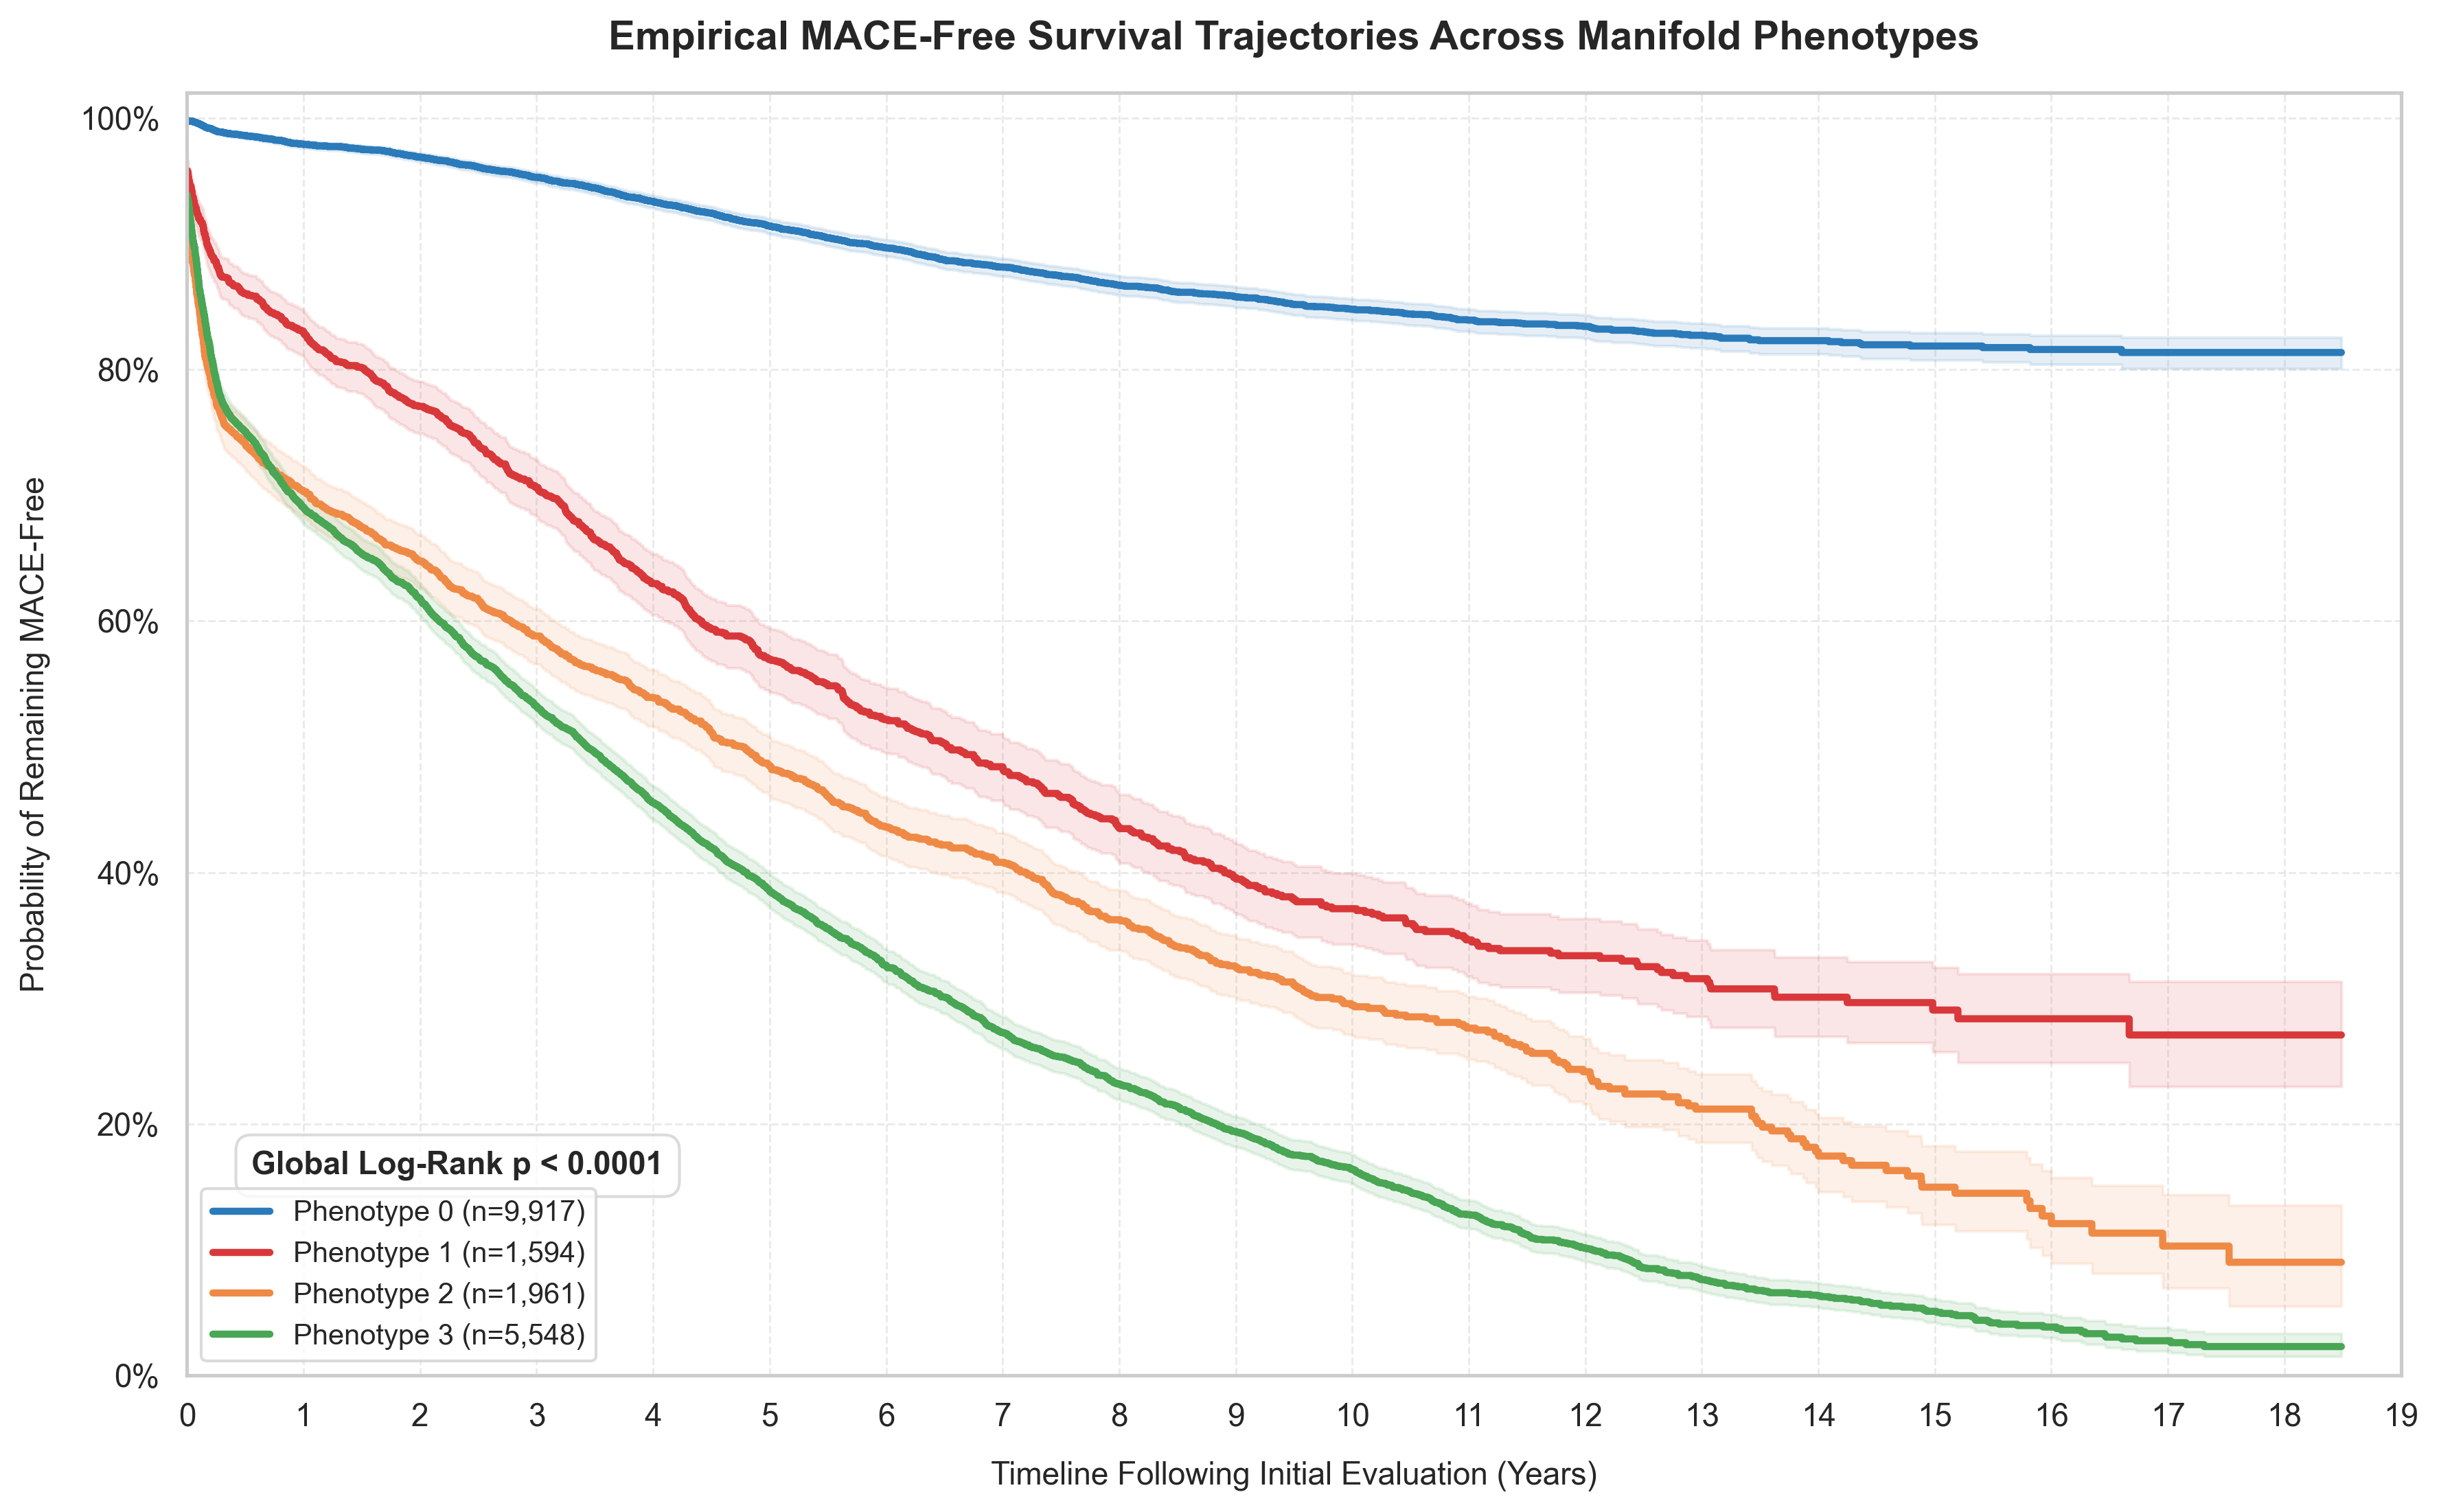

🏆 Success! Graphic generated. Calculated Global Log-Rank p < 0.0001


In [64]:

from lifelines.statistics import multivariate_logrank_test

# =====================================================================
# 1. GENERATE THE CHAMPION PHENOTYPES FOR VALIDATION POPULATION (K=4)
# =====================================================================
print("⏳ Step 1: Projecting validation patient geometry (nn=75, nc=15)...")
champion_umap = UMAP(n_neighbors=75, n_components=15, min_dist=0.0, random_state=42, n_jobs=1)
X_train_umap = champion_umap.fit_transform(X_train_scaled)
X_val_umap = champion_umap.transform(X_val_scaled)

print("⏳ Step 2: Extracting patient phenotyping clusters (K=4)...")
champion_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
_ = champion_kmeans.fit(X_train_umap)  # Fit on training partition
val_clusters = champion_kmeans.predict(X_val_umap)   # Transmit assignments to validation set

# Extract raw timeline structures and convert explicitly from Days to Years
val_durations_days = y_val['time_to_comp_outcome'].fillna(y_val['follow_up_days']).astype(float).values
val_durations_years = val_durations_days / 365.25
val_events = y_val['comp_outcome'].astype(int).values

# Build clean analysis DataFrame
km_df = pd.DataFrame({
    'cluster': val_clusters,
    'timeline_years': val_durations_years,
    'mace_event': val_events
})

# =====================================================================
# 2. RUN OMNIBUS MULTIVARIATE LOG-RANK TEST
# =====================================================================
print("⏳ Step 3: Computing global log-rank test statistics...")
log_rank_results = multivariate_logrank_test(
    event_durations=km_df['timeline_years'],
    groups=km_df['cluster'],
    event_observed=km_df['mace_event']
)
global_p_value = log_rank_results.p_value

# Format p-value to clean medical standard notation
if global_p_value < 0.0001:
    p_value_string = "Global Log-Rank p < 0.0001"
else:
    p_value_string = f"Global Log-Rank p = {global_p_value:.4f}"

# =====================================================================
# 3. INITIALIZE PLOT CANVAS (DOWNWARD MEDICAL LAYOUT)
# =====================================================================
plt.figure(figsize=(12, 7.5), dpi=300)
kmf = KaplanMeierFitter()

cluster_colors = {
    0: '#2b7bba',  # Blue profile
    1: '#d9383a',  # Red profile
    2: '#ef8a46',  # Orange profile
    3: '#49a654'   # Green profile
}

print("⏳ Step 4: Plotting downward KM curves with 95% CIs...")
for cluster_id in sorted(km_df['cluster'].unique()):
    mask = (km_df['cluster'] == cluster_id)
    
    kmf.fit(
        durations=km_df.loc[mask, 'timeline_years'],
        event_observed=km_df.loc[mask, 'mace_event'],
        label=f"Phenotype {cluster_id} (n={mask.sum():,})"
    )
    
    kmf.plot_survival_function(
        color=cluster_colors[cluster_id],
        linewidth=2.5,
        ci_show=True,
        ci_alpha=0.12,
        ci_force_lines=False
    )

# =====================================================================
# 4. POLISH STYLING AND STAMP THE LOG-RANK P-VALUE
# =====================================================================
plt.title("Empirical MACE-Free Survival Trajectories Across Manifold Phenotypes", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Timeline Following Initial Evaluation (Years)", fontsize=11, labelpad=10)
plt.ylabel("Probability of Remaining MACE-Free", fontsize=11, labelpad=10)

# Impose tight clinical constraints on axes
plt.ylim(0.0, 1.02)
max_years = km_df['timeline_years'].max()
plt.xlim(0, max_years)
plt.xticks(np.arange(0, int(np.ceil(max_years)) + 1, 1))

# Convert decimal y-ticks cleanly to percentages
plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) for x in plt.gca().get_yticks()])
plt.grid(color='#e2e2e2', linestyle='--', linewidth=0.7, alpha=0.7)

# --- DYNAMIC TEXT STAMPING ---
# Places the p-value cleanly right above the lower-left legend box
plt.text(
    x=max_years * 0.03, 
    y=0.16, 
    s=p_value_string, 
    fontsize=11, 
    fontweight='bold', 
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='#d3d3d3', boxstyle='round,pad=0.5')
)

plt.legend(frameon=True, facecolor='white', edgecolor='#d3d3d3', loc='lower left', fontsize=10)
plt.tight_layout()
plt.show()

print(f"🏆 Success! Graphic generated. Calculated {p_value_string}")

In [67]:
from sklearn.metrics import silhouette_score
from sklearn.utils import resample

# =====================================================================
# 1. REGENERATE CHAMPION MANIFOLD & K=4 LABELS (TRAINING)
# =====================================================================
print("⏳ Step 1: Projecting training manifold geometry (nn=75, nc=15)...")
champion_umap = UMAP(n_neighbors=75, n_components=15, min_dist=0.0, random_state=42, n_jobs=1)
X_train_umap = champion_umap.fit_transform(X_train_scaled)

print("⏳ Step 2: Extracting training cluster assignments (K=4)...")
champion_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
train_clusters = champion_kmeans.fit_predict(X_train_umap)

# =====================================================================
# 2. CALCULATE EXACT PATIENT ALLOCATIONS (FULL TRAINING COHORT)
# =====================================================================
train_counts = pd.Series(train_clusters).value_counts().sort_index()
train_pcts = pd.Series(train_clusters).value_counts(normalize=True).sort_index() * 100

# =====================================================================
# 3. COMPUTE REPRESENTATIVE MANIFOLD SILHOUETTE PROFILE
# =====================================================================
target_sample_size = 10000
print(f"⏳ Step 3: Drawing a random sample of {target_sample_size:,} patients for silhouette evaluation...")

# Subsample down safely while locking seeds to keep metrics perfectly reproducible
X_sample, clusters_sample = resample(
    X_train_umap, 
    train_clusters, 
    n_samples=target_sample_size, 
    random_state=42, 
    stratify=train_clusters  # Maintains the true population breakdown in the 7k sample
)

print("⏳ Step 4: Computing pairwise Euclidean boundary silhouette score...")
global_silhouette = silhouette_score(X_sample, clusters_sample, metric='euclidean', random_state=42)

# =====================================================================
# 4. PRINT COMPREHENSIVE GEOMETRIC ASSESSMENT REPORT
# =====================================================================
print("\n" + "═"*55)
print("🏆   TRAINING COHORT GEOMETRIC METRICS PROFILE (K=4)   ")
print("═"*55)
print(f"{'Phenotype Group':<18} | {'Patient Count':<13} | {'Percentage':<10}")
print("─"*55)
for cluster_id in train_counts.index:
    count = train_counts[cluster_id]
    pct = train_pcts[cluster_id]
    print(f"Phenotype {cluster_id:<10} | {count:<13,} | {pct:.2f}%")
print("─"*55)
print(f"{'Total Training Set':<18} | {len(train_clusters):<13,} | 100.00%")
print("═"*55)
print(f"🔥 Manifold Silhouette Score (n={target_sample_size:,}) : {global_silhouette:.4f}")
print("═"*55 + "\n")

⏳ Step 1: Projecting training manifold geometry (nn=75, nc=15)...
⏳ Step 2: Extracting training cluster assignments (K=4)...
⏳ Step 3: Drawing a random sample of 10,000 patients for silhouette evaluation...
⏳ Step 4: Computing pairwise Euclidean boundary silhouette score...

═══════════════════════════════════════════════════════
🏆   TRAINING COHORT GEOMETRIC METRICS PROFILE (K=4)   
═══════════════════════════════════════════════════════
Phenotype Group    | Patient Count | Percentage
───────────────────────────────────────────────────────
Phenotype 0          | 29,991        | 52.56%
Phenotype 1          | 4,900         | 8.59%
Phenotype 2          | 5,888         | 10.32%
Phenotype 3          | 16,281        | 28.53%
───────────────────────────────────────────────────────
Total Training Set | 57,060        | 100.00%
═══════════════════════════════════════════════════════
🔥 Manifold Silhouette Score (n=10,000) : 0.5000
═══════════════════════════════════════════════════════



In [69]:
# =====================================================================
# 1. SETUP GEOMETRY & HYBRID FEATURES (REF: PHENOTYPE 0)
# =====================================================================
print("⏳ Step 1: Aligning $K=4$ manifold phenotype structures...")
champion_umap = UMAP(n_neighbors=75, n_components=15, min_dist=0.0, random_state=42, n_jobs=1)
X_train_umap = champion_umap.fit_transform(X_train_scaled)
X_val_umap = champion_umap.transform(X_val_scaled)

champion_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
train_clusters = champion_kmeans.fit_predict(X_train_umap)
val_clusters = champion_kmeans.predict(X_val_umap)

cluster_categories = [0, 1, 2, 3]
train_series = pd.Categorical(train_clusters, categories=cluster_categories)
val_series = pd.Categorical(val_clusters, categories=cluster_categories)

train_dummies = pd.get_dummies(train_series, prefix='pheno', drop_first=False)
val_dummies = pd.get_dummies(val_series, prefix='pheno', drop_first=False)

# Explicitly drop phenotype 0 to lock it as our reference anchor
train_pheno_features = train_dummies.drop(columns=['pheno_0'])
val_pheno_features = val_dummies.drop(columns=['pheno_0'])

X_train_hybrid = np.hstack((X_train_scaled, train_pheno_features.astype(float).values))
X_val_hybrid = np.hstack((X_val_scaled, val_pheno_features.astype(float).values))

t_train = y_train['time_to_comp_outcome'].fillna(y_train['follow_up_days']).astype(float).values
e_train = y_train['comp_outcome'].astype(int).values
t_val = y_val['time_to_comp_outcome'].fillna(y_val['follow_up_days']).astype(float).values
e_val = y_val['comp_outcome'].astype(int).values

# =====================================================================
# 2. FIXED BALANCED MILESTONE EVALUATION FUNCTION
# =====================================================================
def evaluate_balanced_milestone(milestone_years, X_tr, t_tr, e_tr, X_v, t_v, e_v):
    milestone_days = milestone_years * 365.25
    threshold_mapping = {1: 0.45, 3: 0.35, 5: 0.25}
    chosen_threshold = threshold_mapping[milestone_years]
    
    # Apply standard right-censoring filters
    train_valid_mask = (e_tr == 1) | (t_tr >= milestone_days)
    X_tr_filtered = X_tr[train_valid_mask]
    y_tr_binary = np.where((e_tr[train_valid_mask] == 1) & (t_tr[train_valid_mask] <= milestone_days), 1, 0)
    
    val_valid_mask = (e_v == 1) | (t_v >= milestone_days)
    X_v_filtered = X_v[val_valid_mask]
    y_v_binary = np.where((e_v[val_valid_mask] == 1) & (t_v[val_valid_mask] <= milestone_days), 1, 0)
    
    # ADDED: class_weight='balanced' to handle the severe Year 1 event sparsity
    log_reg = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    log_reg.fit(X_tr_filtered, y_tr_binary)
    
    # Extract continuous risk probabilities and apply custom thresholds
    y_prob = log_reg.predict_proba(X_v_filtered)[:, 1]
    y_pred = (y_prob >= chosen_threshold).astype(int)
    
    # Extract metrics
    acc = accuracy_score(y_v_binary, y_pred)
    prec = precision_score(y_v_binary, y_pred, zero_division=0)
    rec = recall_score(y_v_binary, y_pred, zero_division=0)
    
    tn, fp, fn, tp = confusion_matrix(y_v_binary, y_pred).ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    
    return acc, prec, rec, spec, len(y_v_binary)

# =====================================================================
# 3. RUN PIPELINE LOOP
# =====================================================================
milestones = [1, 3, 5]
results = {}

for yr in milestones:
    results[yr] = evaluate_balanced_milestone(yr, X_train_hybrid, t_train, e_train, X_val_hybrid, t_val, e_val)

print("\n" + "═"*70)
print("🏆   CLASS-BALANCED LOGISTIC REGRESSION MILESTONE EVALUATION   ")
print("═"*70)
print(f"{'Horizon':<8} | {'Threshold':<9} | {'Accuracy':<8} | {'Precision':<9} | {'Recall':<8} | {'Specificity':<11}")
print("─"*70)
thresholds_print = {1: "0.45", 3: "0.35", 5: "0.25"}
for yr in milestones:
    acc, prec, rec, spec, n_patients = results[yr]
    thresh = thresholds_print[yr]
    print(f"{yr}-Year  | {thresh:<9} | {acc:.4f}   | {prec:.4f}    | {rec:.4f}   | {spec:.4f}")
print("═"*70 + "\n")

⏳ Step 1: Aligning $K=4$ manifold phenotype structures...

══════════════════════════════════════════════════════════════════════
🏆   CLASS-BALANCED LOGISTIC REGRESSION MILESTONE EVALUATION   
══════════════════════════════════════════════════════════════════════
Horizon  | Threshold | Accuracy | Precision | Recall   | Specificity
──────────────────────────────────────────────────────────────────────
1-Year  | 0.45      | 0.7771   | 0.3847    | 0.8724   | 0.7608
3-Year  | 0.35      | 0.7576   | 0.5009    | 0.9105   | 0.7085
5-Year  | 0.25      | 0.7588   | 0.6062    | 0.9498   | 0.6508
══════════════════════════════════════════════════════════════════════



In [72]:
# =====================================================================
# 1. GENERATE REPRODUCIBLE MANIFOLD PATIENT CLUSTERS (K=4)
# =====================================================================
print("⏳ Step 1: Generating champion manifold layout (nn=75, nc=15)...")
champion_umap = UMAP(n_neighbors=75, n_components=15, min_dist=0.0, random_state=42, n_jobs=1)
# Fits directly using your structured scaled training DataFrame
X_train_umap = champion_umap.fit_transform(X_train_scaled)

print("⏳ Step 2: Assigning patient cluster groupings...")
champion_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
train_clusters = champion_kmeans.fit_predict(X_train_umap)

# =====================================================================
# 2. DEFINE THE SMD PROFILE GENERATOR
# =====================================================================
def calculate_and_print_all_spider_metrics(X_df, cluster_labels):
    """
    Computes SMD for every feature within each cluster vs the rest of the world.
    Prints the complete top 20 rankings to ensure clean scannability.
    """
    df = X_df.copy()
    df['cluster_id'] = cluster_labels
    all_features = list(X_df.columns)
    
    # Isolate variable types based on cardinality rules
    continuous_features = [col for col in all_features if df[col].nunique() > 2]
    binary_features = [col for col in all_features if df[col].nunique() <= 2]
    
    unique_clusters = sorted(df['cluster_id'].unique())
    all_cluster_top_20 = {}
    
    print("\n" + "═"*75)
    print("🏆       COMPLETE TOP 20 DEFINING SMD FEATURES PER MANIFOLD PHENOTYPE       ")
    print("═"*75)
    
    for cluster in unique_clusters:
        cluster_smd_records = []
        
        # Split workspace: Current target cluster vs. everyone else
        in_cluster = df[df['cluster_id'] == cluster]
        out_cluster = df[df['cluster_id'] != cluster]
        
        # --- Continuous SMD Calculations ---
        for col in continuous_features:
            mean1, mean2 = in_cluster[col].mean(), out_cluster[col].mean()
            var1, var2 = in_cluster[col].var(), out_cluster[col].var()
            pooled_sd = np.sqrt((var1 + var2) / 2.0)
            
            smd = abs(mean1 - mean2) / pooled_sd if pooled_sd > 0 else 0.0
            cluster_smd_records.append({'Feature': col, 'SMD': smd, 'Type': 'Continuous'})
            
        # --- Binary SMD Calculations ---
        for col in binary_features:
            p1 = in_cluster[col].astype(float).mean()
            p2 = out_cluster[col].astype(float).mean()
            pooled_binary_var = np.sqrt((p1 * (1.0 - p1) + p2 * (1.0 - p2)) / 2.0)
            
            smd = abs(p1 - p2) / pooled_binary_var if pooled_binary_var > 0 else 0.0
            cluster_smd_records.append({'Feature': col, 'SMD': smd, 'Type': 'Binary'})
            
        # --- Rank and Extract Top 20 ---
        smd_df = pd.DataFrame(cluster_smd_records)
        top_20 = smd_df.sort_values(by='SMD', ascending=False).head(20).reset_index(drop=True)
        all_cluster_top_20[cluster] = top_20
        
        # --- Display the complete table profile ---
        print(f"\n🟩 PHENOTYPE CLUSTER {cluster} vs NOT CLUSTER {cluster} (n={len(in_cluster):,})")
        print("─"*75)
        print(f"{'Rank':<4} | {'Clinical Feature Variable':<32} | {'SMD Value':<10} | {'Type':<10}")
        print("─"*75)
        for idx, row in top_20.iterrows():
            print(f"#{idx+1:<3} | {row['Feature']:<32} | {row['SMD']:.4f}    | {row['Type']:<10}")
        print("─"*75)
        
    print("═"*75 + "\n")
    return all_cluster_top_20

# =====================================================================
# 3. RUN COMPUTATIONS AND GENERATE THE MASTER PROFILE RESULTS
# =====================================================================
# Pass your verified, selected feature training dataframe straight through!
top_features_by_cluster = calculate_and_print_all_spider_metrics(X_train_scaled, train_clusters)

⏳ Step 1: Generating champion manifold layout (nn=75, nc=15)...
⏳ Step 2: Assigning patient cluster groupings...

═══════════════════════════════════════════════════════════════════════════
🏆       COMPLETE TOP 20 DEFINING SMD FEATURES PER MANIFOLD PHENOTYPE       
═══════════════════════════════════════════════════════════════════════════

🟩 PHENOTYPE CLUSTER 0 vs NOT CLUSTER 0 (n=29,991)
───────────────────────────────────────────────────────────────────────────
Rank | Clinical Feature Variable        | SMD Value  | Type      
───────────────────────────────────────────────────────────────────────────
#1   | labs_blood_urea_peri             | 1.4859    | Continuous
#2   | labs_blood_gfr_calc_ckd_epi2021_peri | 1.3021    | Continuous
#3   | demographics_age_index_visit     | 0.9153    | Continuous
#4   | labs_blood_cbc_rdw_peri          | 0.9090    | Continuous
#5   | labs_blood_cbc_hgb_peri          | 0.8941    | Continuous
#6   | ecg_resting_qrs                  | 0.7783    | Contin